En este apartado, se estudia cómo el tipo de titularidad del centro (público/privado) dentro de la comunidad valenciana, puede influir en la nota de la competencia lectora de 2025

In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df_valencia=pd.read_csv('data/pisa_valencia25.csv')

# Codificación en STRATUM: ESP33=publico, ESP34=privado

# PASO 1: PREPARACIÓN DE LAS COLUMNAS Y DATOS (92 valores nulos eliminados)
pv_cols = [f"PV{i}READ" for i in range(1, 11)]
columnas_necesarias=["STRATUM", 'W_FSTUWT',"ESCS"]+pv_cols
df_valencia_titularidad=df_valencia[columnas_necesarias]
df_valencia_titularidad=df_valencia_titularidad.dropna()
print(df_valencia_titularidad.shape)

(1620, 13)


         Media_Lectura  Std_Lectura  Media_ESCS  Std_ESCS  Total_Alumnos
STRATUM                                                                 
ESP33       427.148947    90.472845   -0.199124  1.013319           1111
ESP34       447.835423    92.253927    0.436547  0.925145            509


C:\Users\TB Val 03\AppData\Local\Temp\ipykernel_24260\3668596553.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


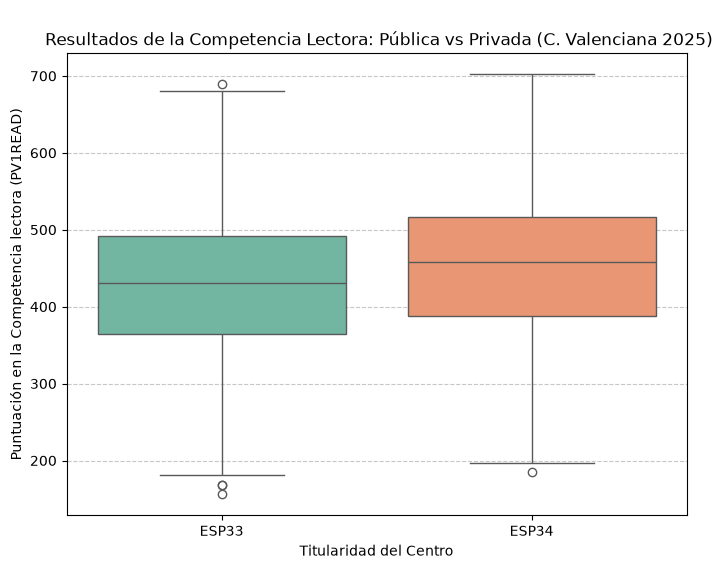

In [7]:
df_tit_estads=df_valencia_titularidad.groupby(df_valencia_titularidad["STRATUM"]).agg(
        Media_Lectura=('PV1READ', 'mean'),
        Std_Lectura=('PV1READ', 'std'),
        Media_ESCS=('ESCS', 'mean'),
        Std_ESCS=('ESCS', 'std'),
        Total_Alumnos=('PV1READ', 'count')
)

print(df_tit_estads)

# 4. Visualización: Diagrama de caja (Boxplot) comparando Competencia Lectora por titularidad
plt.figure(figsize=(8, 6))
sns.boxplot(
    data=df_valencia_titularidad, x="STRATUM", y='PV1READ', palette='Set2'
)
plt.title(
    '\n Resultados de la Competencia Lectora: Pública vs Privada (C. Valenciana 2025)'
)
plt.xlabel('Titularidad del Centro')
plt.ylabel('Puntuación en la Competencia lectora (PV1READ)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.savefig("imgs/grafico_portitularidad.png", dpi=200, bbox_inches="tight")
plt.show()

- Observaciones:

Centros Privados (ESP34): La línea central de la mediana se sitúa aproximadamente en los 460 puntos. Por otro lado, presenta algunos valores atípicos inferiores más marcados (por debajo de 200 puntos, llegando hasta cerca de los 150) y un valor atípico superior cercano a los 700.

Centros Públicos (ESP33): La mediana se encuentra un poco más abajo, alrededor de los 430 puntos. Por otro lado, muestra un límite inferior de los bigotes algo más elevado (~200 puntos) con un pequeño valor atípico por debajo, y el límite superior alcanza los 700 puntos.

En una primera lectura de los datos, sin tener en cuenta otros factores (como el factor socioeconómico), se observa una ligera ventaja en la mediana de puntuación lectora a favor de la red privada en la muestra valenciana.
